# Решение РК1 по ТИНС

**Автор:** Домаскин Егор, студент ИУ9-72Б.

**Вариант**: 8 % 10 + 1 = 8.

---
## Задание

> ## Вариант 8. Функции потерь: от MSE до СЕ
>
> **Цель:** понять, как выбор лосса меняет обучение и поведение модели.
>
> 1. Реализуйте лоссы: MSE, MAE, Huber (регрессия); BCE(бинарная кросс-энтропия), CE(кросс-энтропия. классификация).
> 2. **Регрессия:** сгенерируйте данные с выбросами (ручная синтетическая модель). Обучите одну сеть с MSE, MAE, Huber. Покажите, как выбросы сдвигают модель предсказания при MSE и почему MAE/Huber устойчивее. Постройте графики предсказаний.
> 3. **Классификация:** дисбаланс классов (например, 95/5). Соберите модели для CE и BCE на 2х классах с подгонкой модели под вид потерь и Сравните по метрикам (accuracy, precision, recall, F1). Покажите, почему accuracy не работает.
> 4. **Аналитически** выведите градиенты MSE, MAE, BCE, CE по логитам. Объясните, почему CE+sigmoid даёт «чистый» градиент `(ŷ − y)`.
> 5. Исследуйте: что произойдёт, если обучать регрессию с CE (некорректная постановка)? Продемонстрируйте пример.
> 6. **Контрольные вопросы:**
>    - как выбор лосса связан с постановкой задачи и распределением данных?
>    - Когда оправдан CE?


---
## 0. Подготовка

### 0.1. Импорты

In [56]:
from __future__ import annotations

from typing import Callable

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEEDS = (0, 1, 2, 3, 4)

### 0.2. Настрока графиков

In [47]:
CATEGORICAL = ("#0072B2", "#D55E00", "#009E73", "#8E5FA8")

INK = "#1f2328"
MUTED = "#6a737d"
OUTLIER = "#B22222"

LOSS_COLOR = {
    "MSE": CATEGORICAL[0],
    "MAE": CATEGORICAL[1],
    "Huber": CATEGORICAL[2],
    "BCE": CATEGORICAL[3],
    "CE": CATEGORICAL[1],
    "WBCE": CATEGORICAL[2],
}

LOSS_STYLE = {
    "MSE": "-",
    "MAE": "--",
    "Huber": "-.",
    "BCE": "-",
    "CE": "--",
    "WBCE": "-.",
}


def apply_style() -> None:
    plt.rcParams.update({
        "figure.dpi": 110,
        "figure.figsize": (7.0, 4.0),
        "axes.prop_cycle": plt.cycler(color=list(CATEGORICAL)),
        "axes.grid": True,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "grid.color": MUTED,
        "grid.alpha": 0.25,
        "grid.linewidth": 0.6,
        "lines.linewidth": 2.0,
        "lines.markersize": 5.0,
        "text.color": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "legend.frameon": False,
        "legend.fontsize": 9,
        "figure.facecolor": "white",
        "axes.facecolor": "white",
    })


def label_last(ax, x, y, text: str, color: str, dx: float = 0.0, dy: float = 0.0) -> None:
    ax.annotate(text, xy=(x, y), xytext=(x + dx, y + dy), color=color, fontsize=9, fontweight="bold", va="center")


apply_style()
pd.set_option("display.precision", 6)

---
## 1. Реализация функций потерь (лоссов)

### Функции потерь для задачи регрессии

Пусть модель выдаёт вещественное число $\hat y \in \mathbb{R}$ -- предсказание модели. Обозначим ошибку предсказания как $r = \hat y - y$.

1. **Среднеквадратичная ошибка (Mean Squared Error, MSE)**
    $$L_{\text{MSE}} = r^2, \qquad \frac{\partial L_{\text{MSE}}}{\partial \hat y} = 2r$$

2. **Средняя абсолютная ошибка (Mean Absolute Error, MAE)**
    $$L_{\text{MAE}} = |r|, \qquad \frac{\partial L_{\text{MAE}}}{\partial \hat y} = \operatorname{sign} r \quad (r \neq 0)$$

3. **Функция потерь Хубера (Huber Loss)**
    $$L_{\text{Huber}} = \begin{cases} \tfrac12 r^2, & |r| \le \delta, \\[2pt] \delta\big(|r| - \tfrac12 \delta\big), & |r| > \delta. \end{cases}, \qquad \frac{\partial L_{\text{Huber}}}{\partial \hat y} = \begin{cases} r, & |r| \le \delta, \\ \delta \operatorname{sign} r, & |r| > \delta. \end{cases}$$

### Функции потерь для задачи классификации

Пусть модель выдаёт логит $z \in \mathbb{R}$ (или вектор логитов $z$) -- выход последнего линейного слоя.

1. **Бинарная кросс-энтропия (Binary Cross-Entropy, BCE)**
    Применяется для двух классов, где $y \in \{0, 1\}$. Логит переводится в вероятность с помощью **сигмоиды**:
    $$\text{Активация: } \hat y = \sigma(z) = \frac{1}{1 + e^{-z}}$$
    $$L_{\text{BCE}} = -\big[\,y \ln \hat y + (1-y)\ln(1-\hat y)\,\big], \qquad \frac{\partial L_{\text{BCE}}}{\partial z} = \sigma(z) - y$$

2. **Многоклассовая кросс-энтропия (Cross-Entropy, CE)**
    Применяется для $K$ классов, где $y$ представлен в виде one-hot вектора. Вектор логитов переводится в вектор вероятностей с помощью **софтмакса**:
    $$\text{Активация: } \hat y_k = \mathrm{softmax}(z)_k = \frac{e^{z_k}}{\sum_{j=1}^{K} e^{z_j}}$$
    $$L_{\text{CE}} = -\sum_{k=1}^{K} y_k \ln \hat y_k, \qquad \frac{\partial L_{\text{CE}}}{\partial z} = \mathrm{softmax}(z) - y$$

In [5]:
# === Вспомогательные функции ===

def _process_ndarrays(a: np.ndarray, b: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    if a.shape != b.shape:
        raise ValueError(
            f"Формы не совпадают: {name_a} {a.shape}, {name_b} {b.shape}. "
            f"Приведите их к одинаковой форме, например, через reshape()."
        )
    return a, b


def to_one_hot(y: np.ndarray, num_classes: int) -> np.ndarray:
    return np.eye(num_classes, dtype=np.float64)[np.asarray(y, dtype=int)]


# === Функции активации ===

def sigmoid(z: np.ndarray) -> np.ndarray:
    z = np.asarray(z, dtype=np.float64)
    e = np.exp(-np.abs(z))
    return np.where(z >= 0, 1.0 / (1.0 + e), e / (1.0 + e))


def softplus(z: np.ndarray) -> np.ndarray:
    z = np.asarray(z, dtype=np.float64)
    return np.log1p(np.exp(-np.abs(z))) + np.maximum(z, 0.0)


def softmax(Z: np.ndarray) -> np.ndarray:
    Z = np.asarray(Z, dtype=np.float64)
    e = np.exp(Z - np.max(Z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)


def log_softmax(Z: np.ndarray) -> np.ndarray:
    Z = np.asarray(Z, dtype=np.float64)
    shifted = Z - np.max(Z, axis=1, keepdims=True)
    return shifted - np.log(np.sum(np.exp(shifted), axis=1, keepdims=True))


# === Функции потерь для задач регрессии ===

def mse(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    y_true, y_pred = _process_ndarrays(y_true, y_pred)
    return float(np.mean((y_pred - y_true) ** 2))


def mse_grad(y_true: np.ndarray, y_pred: np.ndarray) -> np.ndarray:
    y_true, y_pred = _process_ndarrays(y_true, y_pred)
    return 2.0 * (y_pred - y_true) / y_true.size


def mae(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    y_true, y_pred = _process_ndarrays(y_true, y_pred)
    return float(np.mean(np.abs(y_pred - y_true)))


def mae_grad(y_true: np.ndarray, y_pred: np.ndarray) -> np.ndarray:
    y_true, y_pred = _process_ndarrays(y_true, y_pred)
    return np.sign(y_pred - y_true) / y_true.size


def huber(y_true: np.ndarray, y_pred: np.ndarray, delta: float = 1.0) -> float:
    y_true, y_pred = _process_ndarrays(y_true, y_pred)
    r = y_pred - y_true
    a = np.abs(r)
    return float(np.mean(np.where(a <= delta, 0.5 * r ** 2, delta * (a - 0.5 * delta))))


def huber_grad(y_true: np.ndarray, y_pred: np.ndarray, delta: float = 1.0) -> np.ndarray:
    y_true, y_pred = _process_ndarrays(y_true, y_pred)
    r = y_pred - y_true
    a = np.abs(r)
    return np.where(a <= delta, r, delta * np.sign(r)) / r.size


REGRESSION_LOSSES: dict[str, tuple[Callable, Callable]] = {
    "MSE": (mse, mse_grad),
    "MAE": (mae, mae_grad),
    "Huber": (huber, huber_grad),
}


# === Функции потерь для задач классификации ===

def bce_from_logits(y_true: np.ndarray, z: np.ndarray) -> float:
    y_true, z = _process_ndarrays(y_true, z)
    return float(np.mean(softplus(z) - y_true * z))


def bce_from_logits_grad(y_true: np.ndarray, z: np.ndarray) -> np.ndarray:
    y_true, z = _process_ndarrays(y_true, z)
    return (sigmoid(z) - y_true) / y_true.size


def wbce_from_logits(y_true: np.ndarray, z: np.ndarray, w_pos: float) -> float:
    y_true, z = _process_ndarrays(y_true, z)
    return float(np.mean(w_pos * y_true * softplus(-z) + (1.0 - y_true) * softplus(z)))


def wbce_from_logits_grad(y_true: np.ndarray, z: np.ndarray, w_pos: float) -> np.ndarray:
    y_true, z = _process_ndarrays(y_true, z)
    return (w_pos * y_true + (1.0 - y_true)) * (sigmoid(z) - y_true) / y_true.size


def bce_from_probs(y_true: np.ndarray, y_pred: np.ndarray, eps: float = 1e-12) -> float:
    y_true, y_pred = _process_ndarrays(y_true, y_pred)
    if eps > 0:
        y_pred = np.clip(y_pred, eps, 1.0 - eps)
    return float(-np.mean(y_true * np.log(y_pred) + (1.0 - y_true) * np.log1p(-y_pred)))


def ce_from_logits(Y: np.ndarray, Z: np.ndarray) -> float:
    Y, Z = _process_ndarrays(Y, Z)
    if Z.ndim != 2:
        raise ValueError(f"Ожидалась матрица (N, K), получено {Z.shape}")
    return float(-np.mean(np.sum(Y * log_softmax(Z), axis=1)))


def ce_from_logits_grad(Y: np.ndarray, Z: np.ndarray) -> np.ndarray:
    Y, Z = _process_ndarrays(Y, Z)
    return (softmax(Z) - Y) / Z.shape[0]


CLASSIFICATION_LOSSES: dict[str, tuple[Callable, Callable]] = {
    "BCE": (bce_from_logits, bce_from_logits_grad),
    "CE": (ce_from_logits, ce_from_logits_grad),
}

### Эксперимент 1. Графики лоссов для задач регрессии и их градиентов

Построим два графика. На левом графике отобразим, какой штраф накладывает каждый лосс за ошибку предсказания $r$. На правом -- производную от этого же штрафа.

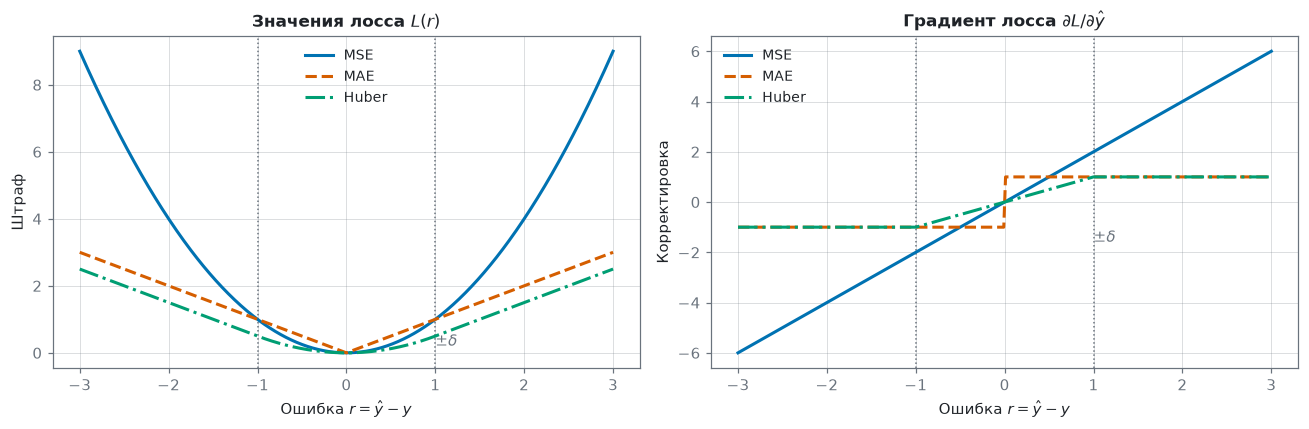

Градиент при ошибке r = 3 (взяли одну удалённую точку):
  MSE    +6.000
  MAE    +1.000
  Huber  +1.000


In [32]:
r_grid = np.linspace(-3.0, 3.0, 601)
y0 = np.array([0.0])

fig, (ax_loss, ax_grad) = plt.subplots(1, 2, figsize=(12.0, 4.0))

for name, (value_fn, grad_fn) in REGRESSION_LOSSES.items():
    values = [value_fn(y0, np.array([r])) for r in r_grid]
    grads = [grad_fn(y0, np.array([r]))[0] for r in r_grid]

    style = dict(color=LOSS_COLOR[name], ls=LOSS_STYLE[name], label=name)
    ax_loss.plot(r_grid, values, **style)
    ax_grad.plot(r_grid, grads, **style)

for ax in (ax_loss, ax_grad):
    for bound in (-1.0, 1.0):
        ax.axvline(bound, color=MUTED, ls=":", lw=1.0, zorder=0)
    ax.set_xlabel("Ошибка $r = \\hat y - y$")
    ax.legend()

ax_loss.set(title="Значения лосса $L(r)$", ylabel="Штраф")
ax_grad.set(title="Градиент лосса $\\partial L / \\partial \\hat y$", ylabel="Корректировка")

ax_loss.annotate("$\\pm\\delta$", xy=(1.0, 0.2), color=MUTED, fontsize=10)
ax_grad.annotate("$\\pm\\delta$", xy=(1.0, -1.6), color=MUTED, fontsize=10)

fig.tight_layout()
plt.show()

print("Градиент при ошибке r = 3 (взяли одну удалённую точку):")
for name, (_v, grad_fn) in REGRESSION_LOSSES.items():
    print(f"  {name:6s} {grad_fn(y0, np.array([3.0]))[0]:+.3f}")

**Что мы видим?**

- **Значения лосса (левый график):** MSE -- парабола, MAE -- галка, Huber -- в центре -- парабола, на границах $\pm \delta$ -- переходит в крылья галки.

- **Градиент лосса (правый график):**
  - MSE: градиент **растёт линейно и неограниченно**. Далекая точка с ошибкой $r = 3$ корректирует параметры модели в 6 раз сильнее, чем точка с небольшой ошибкой $r = 0.5$.
  - MAE: градиент **постоянен (по модулю)**. Все аномалии влияют на модель с одинаковой силой, независимо от величины их отклонения.
  - Huber: градиент **растёт линейно, пока ошибка меньше $\delta$, а затем упирается в потолок $\pm \delta$**. Выбросы с огромной ошибкой не могут скорректировать модель сильнее этого предела.

**Вывод.** Вклад одного выброса в градиент у MSE неограничен, а у MAE и Huber -- ограничен.

---
### Вывод по разделу 1

Реализованы пять функций потерь: MSE, MAE и Huber для регрессии, BCE и CE для
классификации. Каждая из них реализована как значение и как градиент. Всё вручную на NumPy.

Главное различие между регрессионными лоссами видно не на графике значений, а на графике
градиентов: вклад одной точки у MSE растёт линейно и неограниченно (при ошибке $r = 3$
градиент равен 6), у MAE постоянен (1), у Huber ограничен сверху величиной $\delta$.
Это является механизмом устойчивости к выбросам, который нам понадобится далее.

---
## 2. Аналитический вывод градиентов


### MSE

$$
\frac{\partial L}{\partial \hat y}
= \frac{\partial L}{\partial r}\cdot\frac{\partial r}{\partial \hat y}
= \frac{\partial (r^2)}{\partial r}\cdot\frac{\partial r}{\partial \hat y}
= 2r \cdot 1
= 2\,(\hat y - y).
$$


### MAE

$$
\frac{\partial L}{\partial \hat y}
= \frac{\partial L}{\partial r}\cdot\frac{\partial r}{\partial \hat y}
= \frac{\partial (|r|)}{\partial r}\cdot\frac{\partial r}{\partial \hat y}
= \operatorname{sign}(r) \cdot 1
= \begin{cases} +1, & r > 0,\\ -1, & r < 0.\end{cases}
$$

Заметим, что в точке $r = 0$ производной **не существует**: слева предел равен $-1$, справа $+1$. Так что значение в точке $r = 0$ производной назначается. Обычно берут $L'(0) = 0$.


### Huber

$$\frac{\partial L}{\partial \hat y}
= \begin{cases}
    \dfrac{\partial}{\partial r}\Big(\tfrac12 r^2\Big) = r, & |r| \le \delta, \\[8pt]
    \dfrac{\partial}{\partial r}\Big(\delta\big(|r| - \tfrac12\delta\big)\Big)
    = \delta \operatorname{sign}(r), & |r| > \delta .
\end{cases}
$$

Заметим, что $\big|\partial L/\partial \hat y\big| \le \delta$ у Huber и $\le 1$ у MAE при любой ошибке, тогда как у MSE эта величина неограничена.


### BCE

Шаг 1. Производная потери по выходу.
$$L = -\big[\,y \ln \hat y + (1-y)\ln(1-\hat y)\,\big],$$
$$\frac{\partial L}{\partial \hat y}
= -\left[\frac{y}{\hat y} - \frac{1-y}{1-\hat y}\right]
= -\,\frac{y(1-\hat y) - (1-y)\hat y}{\hat y\,(1-\hat y)}
= -\,\frac{y - y\hat y - \hat y + y\hat y}{\hat y\,(1-\hat y)}
= \frac{\hat y - y}{\hat y\,(1-\hat y)} .$$

Шаг 2. Производная сигмоиды.
$$\sigma'(z) = \frac{e^{-z}}{\big(1+e^{-z}\big)^2}
= \frac{1}{1+e^{-z}} \cdot \frac{e^{-z}}{1+e^{-z}}
= \sigma(z)\big(1 - \sigma(z)\big) = \hat y\,(1-\hat y).$$

Шаг 3. Перемножаем.
$$\frac{\partial L}{\partial z}
= \frac{\partial L}{\partial \hat y}\cdot\frac{\partial \hat y}{\partial z}
= \frac{\hat y - y}{\hat y\,(1-\hat y)} \cdot \hat y\,(1-\hat y)
= \boxed{\;\hat y - y\;}$$

Заметим, что градиент равен ошибке предсказания и не содержит производной функции активации. Поэтому он не исчезает, когда модель насыщена.


### CE

Шаг 1. Производная softmax. Заметим, что каждый $\hat y_k$ зависит от всех
логитов сразу (через знаменатель). Поэтому рассмотрим два случая.

При $k = j$. Пусть $S = \sum_j e^{z_j}$:
$$\frac{\partial \hat y_k}{\partial z_k}
= \frac{e^{z_k} S - e^{z_k} e^{z_k}}{S^2}
= \frac{e^{z_k}}{S}\left(1 - \frac{e^{z_k}}{S}\right) = \hat y_k (1 - \hat y_k).$$

При $k \ne j$:
$$\frac{\partial \hat y_k}{\partial z_j}
= e^{z_k} \cdot \left(-\frac{1}{S^2}\right) \cdot e^{z_j}
= -\,\hat y_k \hat y_j .$$

Можем объединить оба случая в одну формулу с помощью символа Кронекера:
$$\frac{\partial \hat y_k}{\partial z_j} = \hat y_k\big(\delta_{kj} - \hat y_j\big).$$

Шаг 2. Перемножаем по цепному правилу:
$$\frac{\partial L}{\partial z_j}
= \sum_{k} \frac{\partial L}{\partial \hat y_k}\cdot\frac{\partial \hat y_k}{\partial z_j}
= \sum_{k} \left(-\frac{y_k}{\hat y_k}\right)\cdot \hat y_k\big(\delta_{kj} - \hat y_j\big)
= -\sum_{k} y_k \big(\delta_{kj} - \hat y_j\big).$$

Шаг 3. Раскрываем сумму. Первое слагаемое оставляет только $k = j$, во втором
$\hat y_j$ выносится, а $\sum_k y_k = 1$:
$$\frac{\partial L}{\partial z_j}
= -y_j + \hat y_j \sum_k y_k = \boxed{\;\hat y_j - y_j\;}$$


### Объясните, почему CE+sigmoid даёт «чистый» градиент `(ŷ − y)`

Предполагаю, что имелось в виду всё же BCE + sigmoid, иначе получается ерунда. Однако даже с этим предположением, вопрос не очень понятен. Мы получили этот результат выше в результате аналитического вывода градиентов. Или имеется в виду что-то другое (мат. стат., ММП, минимизация затухания градиента, ...)?


### Ручной подсчёт и сверка с кодом



In [45]:
# --- Регрессия: y_true = 2.0, y_pred = 3.3, delta = 1.0 ---
y_true_reg = np.array([2.0])
y_pred_reg = np.array([3.3])

r = y_pred_reg[0] - y_true_reg[0]  # 1.3
delta = 1.0


# --- Бинарная классификация: y_true = 1, logit = 0.4 ---
y_true_bin = np.array([1.0])
logits_bin = np.array([0.4])

y_pred_bin = 1.0 / (1.0 + math.exp(-logits_bin[0]))


# --- Многоклассовая классификация: logits = (0.5, -1.0, 2.0), класс = 2 ---
logits_multi = np.array([0.5, -1.0, 2.0])
y_true_class = 2

# Softmax со сдвигом на максимум для численной устойчивости
shifted_logits = logits_multi - logits_multi.max()
exp_logits = np.exp(shifted_logits)
y_pred_multi = exp_logits / exp_logits.sum()


# --- Сравнение аналитических значений с результатами функций ---
rows = [
    (
        "MSE, значение",
        r**2,
        mse(y_true_reg, y_pred_reg),
    ),
    (
        "MSE, градиент",
        2.0 * r,
        mse_grad(y_true_reg, y_pred_reg)[0],
    ),
    (
        "MAE, значение",
        abs(r),
        mae(y_true_reg, y_pred_reg),
    ),
    (
        "MAE, градиент",
        math.copysign(1.0, r),
        mae_grad(y_true_reg, y_pred_reg)[0],
    ),
    (
        "Huber, значение",
        delta * (abs(r) - delta / 2.0),
        huber(y_true_reg, y_pred_reg),
    ),
    (
        "Huber, градиент",
        delta * math.copysign(1.0, r),
        huber_grad(y_true_reg, y_pred_reg)[0],
    ),
    (
        "BCE, значение",
        -math.log(y_pred_bin),
        bce_from_logits(y_true_bin, logits_bin),
    ),
    (
        "BCE, градиент",
        y_pred_bin - y_true_bin[0],
        bce_from_logits_grad(y_true_bin, logits_bin)[0],
    ),
    (
        "CE, значение",
        -math.log(y_pred_multi[y_true_class]),
        ce_from_logits(
            to_one_hot(
                np.array([y_true_class]),
                len(logits_multi),
            ),
            logits_multi.reshape(1, -1),
        ),
    ),
]

table = pd.DataFrame(
    rows,
    columns=["Величина", "Вручную", "Функция"],
)
table["Расхождение"] = (
    table["Вручную"] - table["Функция"]
).abs()
display(
    table.set_index("Величина").style.format(
        {
            "Вручную": "{:.6f}",
            "Функция": "{:.6f}",
            "Расхождение": "{:.1e}",
        }
    )
)


# --- Промежуточные вероятности ---
print(f"sigmoid(0.4) = {y_pred_bin:.6f}")
print(
    "softmax(0.5, -1.0, 2.0) = "
    f"({y_pred_multi[0]:.6f}, "
    f"{y_pred_multi[1]:.6f}, "
    f"{y_pred_multi[2]:.6f}), "
    f"сумма = {y_pred_multi.sum():.6f}"
)


# --- Градиент CE по каждому логиту ---
y_true_multi = to_one_hot(
    np.array([y_true_class]),
    len(logits_multi),
)[0]
manual_ce_grad = y_pred_multi - y_true_multi
code_ce_grad = ce_from_logits_grad(
    y_true_multi.reshape(1, -1),
    logits_multi.reshape(1, -1),
)[0]

print("\nГрадиент CE по трём логитам:")
print(
    "  вручную, y_pred - y_true: "
    f"({manual_ce_grad[0]:+.6f}, "
    f"{manual_ce_grad[1]:+.6f}, "
    f"{manual_ce_grad[2]:+.6f})"
)
print(
    "  из функции:     "
    f"({code_ce_grad[0]:+.6f}, "
    f"{code_ce_grad[1]:+.6f}, "
    f"{code_ce_grad[2]:+.6f})"
)
print(
    f"  сумма компонент = {manual_ce_grad.sum():+.1e} "
    "(должна быть нулём: суммы softmax и one-hot равны единице)"
)

,Вручную,Функция,Расхождение
Величина,,,
"MSE, значение",1.690000,1.690000,0.0e+00
"MSE, градиент",2.600000,2.600000,0.0e+00
"MAE, значение",1.300000,1.300000,0.0e+00
"MAE, градиент",1.000000,1.000000,0.0e+00
"Huber, значение",0.800000,0.800000,0.0e+00
"Huber, градиент",1.000000,1.000000,0.0e+00
"BCE, значение",0.513015,0.513015,0.0e+00
"BCE, градиент",-0.401312,-0.401312,0.0e+00
"CE, значение",0.241311,0.241311,0.0e+00


sigmoid(0.4) = 0.598688
softmax(0.5, -1.0, 2.0) = (0.175290, 0.039113, 0.785597), сумма = 1.000000

Градиент CE по трём логитам:
  вручную, y_pred - y_true: (+0.175290, +0.039113, -0.214403)
  из функции:     (+0.175290, +0.039113, -0.214403)
  сумма компонент = +2.8e-17 (должна быть нулём: суммы softmax и one-hot равны единице)


**Что мы видим?** Все девять величин совпали с кодом (до какой-то точности). Отдельно стоит отметить последнюю строку: сумма компонент градиента CE равна нулю. Это не случайность, а следствие того, что и $\hat y$, и $y$ в сумме по классам дают единицу, поэтому $\sum_j (\hat y_j - y_j) = 1 - 1 = 0$. Физический смысл: softmax умеет лишь перераспределять вероятность между классами, и градиент это свойство сохраняет. То есть прибавить уверенности одному классу можно лишь отняв её у остальных.

---
### Вывод по разделу 2

1. Для MSE, MAE и Huber были получены градиенты при помощи дифференцирования. У MAE в нуле производной не существует, но её искуственно дополняют нулём в этой точке. Huber гладкая, так как в точке склейки производные обеих ветвей совпадают (этому способствует член $-\tfrac12\delta^2$).
2. Для BCE с сигмоидой и для CE с softmax градиент по логиту равен в точности ошибке предсказания: $\partial L/\partial z = \hat y - y$. Причина: дробь от производной логарифма сокращается с производной, потому что логарифм и экспонента взаимно обратны. (// Также есть предположение, что это специально так построили в матстате, но я не уверен в этом.)
3. Выкладки подтверждены численно: девять величин, посчитанных вручную по выведенным формулам, совпали со значениями из ранее написанных функций. Сумма компонент градиента CE равна нулю, как и должно быть.

---
## 3. Регрессия на данных с выбросами

Пусть данные задаются моделью $y_i = f(x_i) + \varepsilon_i$, где $\varepsilon_i$ -- шум. Выбросом назовём наблюдение, ошибка которого не укладывается в распределение шума. Наша задача -- восстановить $f$ по загрязнённой выборке.

Заметим, что для константной модели $\hat y = c$:
$$\arg\min_c \sum_i (c - y_i)^2 = \overline{y} \ \text{(среднее)}, \qquad \arg\min_c \sum_i |c - y_i| = \operatorname{med}(y) \ \text{(медиана)} .$$

Первое получается из $\frac{\partial}{\partial c}\sum (c-y_i)^2 = 2\sum(c - y_i) = 0$, второе -- из $\frac{\partial}{\partial c}\sum|c-y_i| = \sum \operatorname{sign}(c - y_i) = 0$: сумма знаков обращается в ноль, когда слева и справа от $c$ одинаковое число точек. Поэтому обучение с MSE оценивает среднее, обучение с MAE -- медиану, а устойчивость этих двух статистик к выбросам сильно отличается.

### Модель

In [102]:
"""
Мини нейронная сеть, написанная вручную.

Внутренее устройство: скрытые слои -- tanh, выходной слой -- линейный. Выход интерпретируется
в зависимости от задачи:

* регрессия -- выход это предсказание p;
* бинарная классификация -- выход это логит z, сигмоида спрятана внутри BCE;
* многоклассовая -- выход это строка логитов (N, K), softmax спрятан внутри CE.
"""


class MLP:
    """Полносвязная сеть. sizes=(1, 16, 16, 1) -- вход 1, два скрытых по 16, выход 1."""

    def __init__(self, sizes: tuple[int, ...], seed: int = 0, activation: str = "tanh") -> None:
        if len(sizes) < 2:
            raise ValueError(f"нужно минимум два размера (вход и выход), получено {sizes}")
        if activation != "tanh":
            raise ValueError(f"поддерживается только 'tanh', получено {activation!r}")
        self.sizes = tuple(sizes)
        self.activation = activation
        rng = np.random.default_rng(seed)
        self.W: list[np.ndarray] = []
        self.b: list[np.ndarray] = []
        for n_in, n_out in zip(self.sizes[:-1], self.sizes[1:]):
            limit = math.sqrt(6.0 / (n_in + n_out))
            self.W.append(rng.uniform(-limit, limit, size=(n_in, n_out)))
            self.b.append(np.zeros(n_out))
        self._cache: dict[str, list[np.ndarray]] | None = None

    # === Проходы ===

    def _propagate(self, X: np.ndarray, remember: bool) -> np.ndarray:
        X = np.asarray(X, dtype=np.float64)
        if X.ndim != 2 or X.shape[1] != self.sizes[0]:
            raise ValueError(f"ожидался вход формы (N, {self.sizes[0]}), получено {X.shape}")
        last = len(self.W) - 1
        a = X
        activations = [a]
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            z = a @ W + b
            a = z if i == last else np.tanh(z)
            activations.append(a)
        if remember:
            self._cache = {"a": activations}
        return a

    def forward(self, X: np.ndarray) -> np.ndarray:
        """Прямой проход с запоминанием: для обратного прохода."""
        return self._propagate(X, remember=True)

    def predict(self, X: np.ndarray) -> np.ndarray:
        """Прямой проход без запоминания: для валидации и графиков."""
        return self._propagate(X, remember=False)

    def backward(self, dL_dout: np.ndarray) -> list[tuple[np.ndarray, np.ndarray]]:
        """Обратный проход."""
        if self._cache is None:
            raise RuntimeError("backward без forward: активации не сохранены")
        activations = self._cache["a"]
        delta = np.asarray(dL_dout, dtype=np.float64)
        if delta.shape != activations[-1].shape:
            raise ValueError(
                f"форма градиента {delta.shape} не совпадает с формой выхода "
                f"{activations[-1].shape}"
            )
        grads: list[tuple[np.ndarray, np.ndarray]] = [(np.empty(0), np.empty(0))] * len(self.W)
        for i in reversed(range(len(self.W))):
            grads[i] = (activations[i].T @ delta, delta.sum(axis=0))
            if i > 0:
                delta = (delta @ self.W[i].T) * (1.0 - activations[i] ** 2)
        return grads

    # === Параметры ===

    def step(self, grads: list[tuple[np.ndarray, np.ndarray]], lr: float) -> None:
        """Шаг градиентного спуска."""
        for i, (dW, db) in enumerate(grads):
            self.W[i] -= lr * dW
            self.b[i] -= lr * db

    def parameters(self) -> list[np.ndarray]:
        """Все массивы параметров: [W0, b0, W1, b1, ...]."""
        out: list[np.ndarray] = []
        for W, b in zip(self.W, self.b):
            out.extend([W, b])
        return out


# === Обучение ===

def fit(
    model: MLP,
    X: np.ndarray,
    y: np.ndarray,
    value_fn: Callable[[np.ndarray, np.ndarray], float],
    grad_fn: Callable[[np.ndarray, np.ndarray], np.ndarray],
    lr: float,
    epochs: int,
    X_val: np.ndarray | None = None,
    y_val: np.ndarray | None = None
) -> dict[str, list[float]]:
    """Обычный градиентный спуск."""

    history: dict[str, list[float]] = {"train": [], "val": []}
    for _ in range(epochs):
        out = model.forward(X)
        history["train"].append(value_fn(y, out))
        if X_val is not None:
            history["val"].append(value_fn(y_val, model.predict(X_val)))
        model.step(model.backward(grad_fn(y, out)), lr)
    history["train"].append(value_fn(y, model.predict(X)))
    if X_val is not None:
        history["val"].append(value_fn(y_val, model.predict(X_val)))
    return history


def numeric_param_grad(
    model: MLP,
    X: np.ndarray,
    y: np.ndarray,
    value_fn: Callable[[np.ndarray, np.ndarray], float],
    h: float = 1e-6
) -> list[tuple[np.ndarray, np.ndarray]]:
    """Проверка обратного прохода."""
    def loss_now() -> float:
        return value_fn(y, model.predict(X))

    grads: list[tuple[np.ndarray, np.ndarray]] = []
    for W, b in zip(model.W, model.b):
        grads.append((_numeric_for(W, loss_now, h), _numeric_for(b, loss_now, h)))
    return grads


def _numeric_for(arr: np.ndarray, loss_now: Callable[[], float], h: float) -> np.ndarray:
    grad = np.zeros_like(arr)
    it = np.nditer(arr, flags=["multi_index"])
    while not it.finished:
        idx = it.multi_index
        original = arr[idx]
        arr[idx] = original + h
        f_plus = loss_now()
        arr[idx] = original - h
        f_minus = loss_now()
        arr[idx] = original
        grad[idx] = (f_plus - f_minus) / (2.0 * h)
        it.iternext()
    return grad


def train(name, X, y, lr, epochs, seed):
    value_fn, grad_fn = REGRESSION_LOSSES[name]
    model = MLP(ARCH, seed=seed)
    history = fit(model, X, y, value_fn, grad_fn, lr=lr, epochs=epochs)
    return model, history

### Функции для генерации синтетики и разделения данных

In [86]:
"""
Синтетические данные для экспериментов.
"""

X_MIN, X_MAX = -3.0, 3.0


def true_function(x: np.ndarray) -> np.ndarray:
    """Функция, по которой генерируются данные."""
    return 1.5 * np.sin(1.5 * x) + 0.5 * x


def make_regression_with_outliers(
    n: int = 200,
    noise: float = 0.15,
    outlier_frac: float = 0.05,
    outlier_shift: float = 6.0,
    seed: int = 0
) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Создает данные для регрессии с шумом и выбросами."""

    if not 0.0 <= outlier_frac <= 1.0:
        raise ValueError(f"outlier_frac должна быть в [0, 1], получено {outlier_frac}")
    rng = np.random.default_rng(seed)
    x = np.linspace(X_MIN, X_MAX, n).reshape(-1, 1)
    y = true_function(x) + rng.normal(scale=noise, size=(n, 1))

    is_outlier = np.zeros(n, dtype=bool)
    n_out = int(round(n * outlier_frac))
    if n_out:
        picked = rng.choice(n, size=n_out, replace=False)
        is_outlier[picked] = True
        y[picked] += outlier_shift
    return x, y, is_outlier


def make_imbalanced_2d(
    n: int = 2000,
    pos_frac: float = 0.05,
    sep: float = 1.8,
    seed: int = 0
) -> tuple[np.ndarray, np.ndarray]:
    """Создает два класса точек с разным количеством объектов."""

    if not 0.0 < pos_frac < 1.0:
        raise ValueError(f"pos_frac должна быть в (0, 1), получено {pos_frac}")
    rng = np.random.default_rng(seed)
    n_pos = int(round(n * pos_frac))
    n_neg = n - n_pos
    X = np.vstack([rng.normal(loc=0.0, scale=1.0, size=(n_neg, 2)),
                   rng.normal(loc=sep, scale=1.0, size=(n_pos, 2))])
    y = np.concatenate([np.zeros(n_neg, dtype=int), np.ones(n_pos, dtype=int)])
    order = rng.permutation(n)
    return X[order], y[order]


def split_three(
    X: np.ndarray,
    y: np.ndarray,
    frac: tuple[float, float, float] = (0.6, 0.2, 0.2),
    seed: int = 0,
    stratify: bool = False
) -> tuple[tuple[np.ndarray, np.ndarray], ...]:
    """Делит данные на обучающую, валидационную и тестовую выборки."""

    X = np.asarray(X)
    y = np.asarray(y)
    if len(frac) != 3 or abs(sum(frac) - 1.0) > 1e-9:
        raise ValueError(f"frac должна быть тройкой с суммой 1, получено {frac}")
    if len(X) != len(y):
        raise ValueError(f"разные длины X и y: {len(X)} и {len(y)}")

    rng = np.random.default_rng(seed)
    labels = y.reshape(len(y), -1)[:, 0] if y.ndim > 1 else y
    groups = [np.flatnonzero(labels == c) for c in np.unique(labels)] if stratify \
        else [np.arange(len(y))]

    buckets: list[list[np.ndarray]] = [[], [], []]
    for group in groups:
        shuffled = rng.permutation(group)
        n_first = int(round(frac[0] * len(group)))
        n_second = int(round(frac[1] * len(group)))
        for bucket, chunk in zip(buckets, (shuffled[:n_first],
                                           shuffled[n_first:n_first + n_second],
                                           shuffled[n_first + n_second:])):
            bucket.append(chunk)

    parts = []
    for bucket in buckets:
        idx = rng.permutation(np.concatenate(bucket))
        parts.append((X[idx], y[idx]))
    return tuple(parts)

**Как честно оценить качество моделей?**

Сравнение модели по значениям их лоссов некорректно, потому что это разные величины и в различных единицах. Оценка по метрике MSE на зашумленных тестовых данных также является некорректной, так как это искусственно завышает качество модели, обученной с помощью MSE.

Так как наши данные являются синтетическими и нам известна зависимость f(x), то для исключения влияния шума и случайных выбросов, качество оценивается по метрике RMSE относительно известной функции f(x) на плотной незашумленной сетке точек:

$$\text{RMSE}_{true} = \sqrt{\frac{1}{M}\sum_{j=1}^{M}\big(\hat y(x_j) - f(x_j)\big)^2}$$

где:
* f(x_j) -- истинное значение функции в точке x_j;
* $\hat y(x_j)$ -- предсказание модели;
* M -- количество точек на сетке.


**Скорость обучения.** У разных лоссов должна быть разной: у MSE градиент пропорционален
ошибке, у MAE по модулю всегда единица. Единая скорость обучения может вредить кому-то из них (не успеет дообучиться).


In [103]:
def rmse_to_truth(model):
    y_pred = model.predict(x_grid)
    return np.sqrt(np.mean((y_pred - y_true) ** 2))

### Эксперимент 2

Три одинаковые модели, отличающиеся лишь лоссами. Пять сидов, чтобы различия нельзя было списать на удачу.

In [110]:
ARCH = (1, 16, 16, 1)
EPOCHS = 3000
LR_SEARCH_EPOCHS = 1500
SWEEP_SEEDS = (0, 1, 2)
LR_CANDIDATES = (0.1, 0.03, 0.01, 0.003)

X_reg, y_reg, is_out = make_regression_with_outliers(n=200, seed=0)
x_grid = np.linspace(X_reg.min(), X_reg.max(), 400).reshape(-1, 1)
y_true = true_function(x_grid)

search = []
for name in REGRESSION_LOSSES:
    for lr in LR_CANDIDATES:
        finals = [train(name, X_reg, y_reg, lr, LR_SEARCH_EPOCHS, seed)[1]["train"][-1] for seed in (0, 1)]
        search.append({"лосс": name, "lr": lr, "свой лосс (среднее по 2 сидам)": np.mean(finals)})

search_table = pd.DataFrame(search).pivot(index="lr", columns="лосс", values="свой лосс (среднее по 2 сидам)")
BEST_LR = {name: float(search_table[name].idxmin()) for name in REGRESSION_LOSSES}

print("Подбор скорости обучения (значение собственного лосса, меньше -- лучше):")
display(search_table.style.format("{:.4f}").highlight_min(axis=0, props="font-weight: bold;"))
print("Выбираем:", ", ".join(f"{k} -> {v}" for k, v in BEST_LR.items()))

Подбор скорости обучения (значение собственного лосса, меньше -- лучше):


лосс,Huber,MAE,MSE
lr,,,
0.003000,0.3559,0.5390,1.6598
0.010000,0.2919,0.4241,1.6382
0.030000,0.2824,0.4719,1.6323
0.100000,0.2875,0.4901,1.6018


Выбираем: MSE -> 0.1, MAE -> 0.01, Huber -> 0.03


In [106]:
BEST_LR = {"MSE": 0.1, "MAE": 0.01, "Huber": 0.03}
print("Скорость обучения:", BEST_LR)

Скорость обучения: {'MSE': 0.1, 'MAE': 0.01, 'Huber': 0.03}


In [111]:
runs = {name: [] for name in REGRESSION_LOSSES}
for name in REGRESSION_LOSSES:
    for seed in SEEDS:
        model, history = train(name, X_reg, y_reg, BEST_LR[name], EPOCHS, seed)
        runs[name].append({
            "model": model, "history": history,
            "pred": model.predict(grid),
            "rmse": rmse_to_truth(model),
            "mae": float(np.mean(np.abs(model.predict(grid) - truth))),
        })

rows = []
for name, trials in runs.items():
    rmses = np.array([t["rmse"] for t in trials])
    maes = np.array([t["mae"] for t in trials])
    rows.append({
        "лосс": name, "lr": BEST_LR[name],
        "RMSE к истине": f"{rmses.mean():.4f} ± {rmses.std():.4f}",
        "MAE к истине": f"{maes.mean():.4f} ± {maes.std():.4f}",
        "RMSE (худший сид)": f"{rmses.max():.4f}",
    })
display(pd.DataFrame(rows).set_index("лосс"))

,lr,RMSE к истине,MAE к истине,RMSE (худший сид)
лосс,,,,
MSE,0.10,0.4643 ± 0.0126,0.3232 ± 0.0052,0.4869
MAE,0.01,0.0995 ± 0.0123,0.0843 ± 0.0085,0.1124
Huber,0.03,0.1141 ± 0.0008,0.0946 ± 0.0007,0.1149


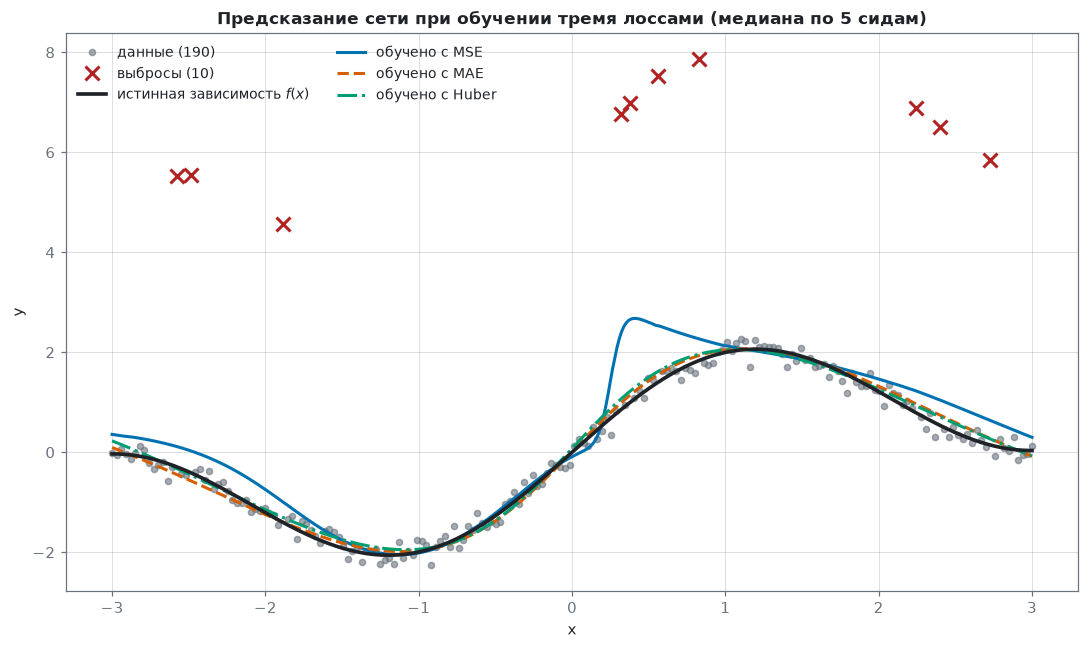

In [113]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(X_reg[~is_out], y_reg[~is_out], "o", color=MUTED, ms=4, alpha=0.6, label=f"данные ({(~is_out).sum()})", zorder=2)
ax.plot(X_reg[is_out], y_reg[is_out], "x", color=OUTLIER, ms=9, mew=2, label=f"выбросы ({is_out.sum()})", zorder=5)
ax.plot(grid, truth, color=INK, lw=2.4, label="истинная зависимость $f(x)$", zorder=4)

for name, trials in runs.items():
    median_pred = np.median(np.stack([t["pred"] for t in trials]), axis=0)
    ax.plot(grid, median_pred, color=LOSS_COLOR[name], ls=LOSS_STYLE[name], lw=2.0, label=f"обучено с {name}", zorder=3)

ax.set_title("Предсказание сети при обучении тремя лоссами (медиана по 5 сидам)")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(loc="upper left", ncols=2)
fig.tight_layout()
plt.show()

**Что мы видим?**

Кривая, обученная с MSE, изгибается в сторону выбросов и даже тянется к ним:

* самое заметное -- горб при $x \approx 0.4$, которые тянется к месту, где сгруппированы 4 выброса;
* на краях ($x \approx -3$ и $x$ от $2.5$ до $3$), где сгруппированы остальные выбросы, кривая тоже приподнята над истинной и тянется к выбросам;
* а на участке от $-1.5$ до $-0.5$, где выбросов нет, MSE идёт практически по истинной зависимости.

Почему? Квадратичный штраф делает десять удалённых точек настолько дорогими, что ради них выгодно испортить форму кривой в их окрестности.

А вот кривые MAE и Huber визуально почти слились с истинной зависимостью на всём отрезке.

---
### Вывод по разделу 3

1. Механизм смещения зависит от того, какую статистику оценивает лосс. Минимум квадратичной
   потери есть среднее, минимум модуля -- медиана. При обучении сети это также проявляется:
   MSE оценивает среднее, MAE -- медиану. А среднее выбросы сдвигают, медиана их не замечает.

2. Эксперимент подтверждает смещение. На данных с 5 % выбросов кривая, обученная
   с MSE, изгибается в их сторону: горб до около 2.7 там, где истинное значение около 0.6.
   Расхождение с истинной зависимостью 0.464 против 0.100 у MAE и 0.114 у Huber -- почти
   впятеро. Разброс по пяти сидам ($\pm 0.013$) на порядок меньше этого разрыва, так что
   списать его на удачу нельзя.

3. Причина была установлена нами ранее: градиент MSE растёт пропорционально ошибке, поэтому
   одна далёкая точка перевешивает десятки близких. У MAE вклад постоянен, у Huber --
   ограничен величиной $\delta$.

---
## 4. Классификация при дисбалансе классов

### Метрики

In [114]:

"""Метрики для бинарной классификации."""


def _as_binary(y: np.ndarray, name: str) -> np.ndarray:
    """Проверяет, что метки равны 0 или 1."""
    arr = np.asarray(y).reshape(-1)
    if arr.size == 0:
        raise ValueError(f"{name}: пустой массив")
    unique = np.unique(arr)
    if not np.all(np.isin(unique, (0, 1))):
        raise ValueError(f"{name}: метки должны быть 0 или 1, встречены {unique}")
    return arr.astype(int)


def confusion(y_true: np.ndarray, y_pred: np.ndarray) -> tuple[int, int, int, int]:
    """Возвращает TP, FP, FN и TN."""
    t = _as_binary(y_true, "y_true")
    p = _as_binary(y_pred, "y_pred")
    if t.shape != p.shape:
        raise ValueError(f"размеры не совпадают: {t.shape} и {p.shape}")
    return (
        int(np.sum((t == 1) & (p == 1))),
        int(np.sum((t == 0) & (p == 1))),
        int(np.sum((t == 1) & (p == 0))),
        int(np.sum((t == 0) & (p == 0))),
    )


def accuracy(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Доля правильных предсказаний."""
    tp, fp, fn, tn = confusion(y_true, y_pred)
    return (tp + tn) / (tp + fp + fn + tn)


def precision(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Доля правильных ответов среди всех срабатываний."""
    tp, fp, _fn, _tn = confusion(y_true, y_pred)
    return tp / (tp + fp) if tp + fp else 0.0


def recall(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """Доля найденных объектов класса 1."""
    tp, _fp, fn, _tn = confusion(y_true, y_pred)
    return tp / (tp + fn) if tp + fn else 0.0


def f_beta(y_true: np.ndarray, y_pred: np.ndarray, beta: float = 1.0) -> float:
    """F-мера, которая позволяет менять важность точности и полноты."""
    p = precision(y_true, y_pred)
    r = recall(y_true, y_pred)
    denominator = beta ** 2 * p + r
    return (1 + beta ** 2) * p * r / denominator if denominator else 0.0


def f1(y_true: np.ndarray, y_pred: np.ndarray) -> float:
    """F1 -- среднее гармоническое точности и полноты."""
    return f_beta(y_true, y_pred, beta=1.0)


def report(y_true: np.ndarray, y_pred: np.ndarray) -> dict[str, float]:
    """Собирает все метрики в один словарь."""
    tp, fp, fn, tn = confusion(y_true, y_pred)
    return {
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
        "accuracy": accuracy(y_true, y_pred),
        "precision": precision(y_true, y_pred),
        "recall": recall(y_true, y_pred),
        "f1": f1(y_true, y_pred),
    }


### Данные и модели

Две модели обучаются на одних и тех же данных и отличаются только выходами и лоссами:

* под BCE -- один выход (логит), вероятность берётся сигмоидой;
* под CE -- два выхода (по логиту на класс), вероятности берутся softmax.

Третья модель -- WBCE, где штраф за ошибку на редком классе умножен на $w = N_0 / N_1$.
Четвёрная -- константная: всегда отвечает "класс 0".

In [116]:
X_cls, y_cls = make_imbalanced_2d(n=2000, pos_frac=0.05, seed=0)
(X_tr, y_tr), (X_val, y_val), (X_te, y_te) = split_three(X_cls, y_cls, seed=0, stratify=True)

W_POS = float((y_tr == 0).sum() / (y_tr == 1).sum())
Q0 = float(max((y_cls == 0).mean(), (y_cls == 1).mean()))

y_tr_col, y_val_col = y_tr.reshape(-1, 1).astype(float), y_val.reshape(-1, 1).astype(float)
Y_tr_oh = to_one_hot(y_tr, 2)

print(f"обучающая {len(y_tr)} (единиц {y_tr.sum()}), валидационная {len(y_val)} (единиц {y_val.sum()}), тестовая {len(y_te)} (единиц {y_te.sum()})")
print(f"доля большинства q0 = {Q0:.3f}  ->  осмысленная accuracy лежит в [{Q0:.2f}, 1]")
print(f"вес редкого класса w = N0/N1 = {W_POS:.1f}")

обучающая 1200 (единиц 60), валидационная 400 (единиц 20), тестовая 400 (единиц 20)
доля большинства q0 = 0.950  ->  осмысленная accuracy лежит в [0.95, 1]
вес редкого класса w = N0/N1 = 19.0


In [122]:
CLS_ARCH_BCE = (2, 16, 1)
CLS_ARCH_CE = (2, 16, 2)
CLS_EPOCHS = 2000
CLS_LR = 0.03

def train_classifiers(seed):
    """Обучает три модели с разными функциями потерь."""
    m_bce = MLP(CLS_ARCH_BCE, seed=seed)
    fit(m_bce, X_tr, y_tr_col, bce_from_logits, bce_from_logits_grad,
        lr=CLS_LR, epochs=CLS_EPOCHS)

    m_ce = MLP(CLS_ARCH_CE, seed=seed)
    fit(m_ce, X_tr, Y_tr_oh, ce_from_logits, ce_from_logits_grad,
        lr=CLS_LR, epochs=CLS_EPOCHS)

    m_w = MLP(CLS_ARCH_BCE, seed=seed)
    fit(m_w, X_tr, y_tr_col,
        lambda a, b: wbce_from_logits(a, b, W_POS),
        lambda a, b: wbce_from_logits_grad(a, b, W_POS),
        lr=CLS_LR, epochs=CLS_EPOCHS)

    return {"BCE": m_bce, "CE": m_ce, "WBCE": m_w}


def probabilities(name, model, X):
    """Возвращает вероятности принадлежности к классу 1."""
    out = model.predict(X)
    return softmax(out)[:, 1] if name == "CE" else sigmoid(out).ravel()


trained = {seed: train_classifiers(seed) for seed in SEEDS}
print(f"Обучено {len(trained) * 3} моделей: по три на каждый из {len(SEEDS)} сидов")

Обучено 15 моделей: по три на каждый из 5 сидов


In [123]:
rows = []
for name in ("BCE", "CE", "WBCE"):
    per_seed = []
    for seed in SEEDS:
        pred = (probabilities(name, trained[seed][name], X_val) > 0.5).astype(int)
        per_seed.append(report(y_val, pred))
    stats = {k: (np.mean([r[k] for r in per_seed]), np.std([r[k] for r in per_seed])) for k in ("accuracy", "precision", "recall", "f1")}
    rows.append({
        "модель": name,
        **{k: f"{m:.3f} ± {s:.3f}" for k, (m, s) in stats.items()},
        "TP": int(np.mean([r["TP"] for r in per_seed])),
        "FN": int(np.mean([r["FN"] for r in per_seed]))
    })

const_pred = np.zeros_like(y_val)
const = report(y_val, const_pred)
rows.append({
    "модель": "константа 'класс 0'",
    **{k: f"{const[k]:.3f}" for k in ("accuracy", "precision", "recall", "f1")},
    "TP": const["TP"],
    "FN": const["FN"]
})

display(pd.DataFrame(rows).set_index("модель"))
print(f"Напоминание: q0 = {Q0:.3f}. Всё, что ниже этого, хуже константы.")

,accuracy,precision,recall,f1,TP,FN
модель,,,,,,
BCE,0.965 ± 0.000,0.800 ± 0.000,0.400 ± 0.000,0.533 ± 0.000,8,12
CE,0.968 ± 0.000,0.818 ± 0.000,0.450 ± 0.000,0.581 ± 0.000,9,11
WBCE,0.911 ± 0.001,0.344 ± 0.003,0.850 ± 0.000,0.490 ± 0.003,17,3
константа 'класс 0',0.950,0.000,0.000,0.000,0,20


Напоминание: q0 = 0.950. Всё, что ниже этого, хуже константы.


**Что мы видим?**

Константная модель получает accuracy 0.950, не найдя ни одного объекта редкого класса: её recall равен нулю, precision -- тоже. Обученная модель получает 0.965. Разница в accuracy -- около 1.58%, а вот разница в полезности абсолютная: обученная модель находит 8 редких объектов из 20, константная -- 0 из 20.

**Вот почему accuracy при дисбалансе не метрика, а нечто бесполезное**: она почти польностью определяется большинством. Правильная оценка начинается с recall (т.е. какую долю редких объектов нашли) и precision (т.е. можно ли верить срабатыванию).

А что делает взвешивание? Подняв цену ошибки на редком классе в 19 раз, мы получаем совсем другой результат: recall вырастает с 0.400 до 0.850 -- найдено 17 объектов из 20 вместо 8, однако precision падает с 0.800 до 0.344, то есть теперь 2/3 срабатываний ложные (32 ложных против 2). F-мера при этом не улучшилась: 0.490 против 0.533.

Это важный и не совсем ожидаемый результат: взвешивание не делает модель однозначно лучше, а меняет её поведение. Оно помогает находить больше редких объектов, но увеличивает число ложных срабатываний.

Вес $w = N_0/N_1$ не обязательно является лучшим выбором. Он просто уравнивает вклад двух классов в ошибку. На практике вес нужно подбирать в зависимости от задачи: что хуже -- пропустить редкий объект или ошибочно принять обычный за редкий? Насколько надёжны результаты?

В валидации всего 20 редких объектов, поэтому нахождение или пропуск одного объекта меняет recall на 0.05. Из-за этого даже небольшие изменения в предсказаниях заметно влияют на метрики.

Например, разница между BCE и CE по F1 (0.533 и 0.581) связана всего с одним дополнительно найденным объектом: 8 против 9. По такой маленькой выборке нельзя уверенно сказать, что одна модель лучше другой.

А вот разница между обычной и взвешенной BCE гораздо заметнее: recall вырос с 0.400 до 0.850, то есть модель нашла на 9 редких объектов больше. Это уже существенное изменение поведения модели, хотя и с увеличением числа ложных срабатываний.

---
### Вывод по разделу 4

1. Accuracy может вводить в заблуждение при дисбалансе классов. Константная модель получает accuracy = 0.950, но не находит ни одного редкого объекта. Обычная BCE получает 0.965 и находит 8 из 20. Поэтому для оценки модели важно смотреть также на recall и precision.
   
2. Взвешивание помогает находить больше редких объектов. При весе $w = N_0/N_1 = 19$ recall увеличивается с 0.400 до 0.850: модель находит 17 объектов из 20 вместо 8. Однако precision падает с 0.800 до 0.344, а число ложных срабатываний растёт с 2 до 32.
   
3. Взвешивание меняет баланс между ошибками, но не гарантирует улучшения качества. F1 у взвешенной BCE составляет 0.490 против 0.533 у обычной BCE. Модель находит больше редких объектов, но чаще ошибается. Выбор веса зависит от задачи: что важнее -- не пропустить редкий объект или уменьшить число ложных срабатываний.
   
4. Разница между BCE и CE небольшая. CE находит 9 редких объектов, а BCE -- 8. Их F1 составляет 0.581 и 0.533 соответственно. По такой маленькой выборке нельзя уверенно утверждать, что CE лучше BCE.
   
5. Результаты зависят от размера выборки. В валидации всего 20 редких объектов, поэтому нахождение или пропуск одного объекта меняет recall на 0.05. Из-за этого метрики чувствительны к отдельным предсказаниям. Для более уверенного сравнения моделей полезно провести дополнительные эксперименты на разных выборках.

---
## 5. Регрессия через кросс-энтропию

Кросс-энтропия отвечает на вопрос "насколько модель была уверена в том, что произошло". Вопрос имеет смысл, только если на "произошло" отвечаем да или нет. То есть спросить, например, про рост человека нельзя: событие "рост равен 184" не случалось и не не случалось. Оно просто число.

Рассмотрим 3 сценария:
* (А) подставить числа как есть -- должна сломаться арифметика;
* (Б) сжать числа в отрезок $[0,1]$ и сделать вид, что это вероятности -- работает, но решает другую задачу;
* (В) нарезать числа на интервалы и честно классифицировать -- работает, но теряет информацию о том, что числа упорядочены.


### Сценарий (а). Подставить числа как есть

Логарифм в кросс-энтропии берётся от предсказания, а не от цели. Поэтому два случая ведут себя очень по-разному.

In [125]:
# (а1) Предсказание -- не вероятность: выход линейного слоя может быть отрицательным.
with np.errstate(divide="ignore", invalid="ignore"):
    broken = bce_from_probs(np.array([1.0]), np.array([-0.3]), eps=0.0)
    hidden = bce_from_probs(np.array([1.0]), np.array([-0.3]), eps=1e-12)

print("(а1) предсказание -0.3 подано в BCE как вероятность:")
print(f"     без обрезки (eps = 0):     L = {broken}")
print(f"     с обрезкой (eps = 1e-12):  L = {hidden:.3f}   <-- ошибка СПРЯТАНА")
print("     Причина: ln(-0.3) не определён. Обрезка в [eps, 1-eps] (как в sklearn.metrics.log_loss?), подменяет -0.3 на eps и возвращает конечное число.")

# (а2) Цель -- не индикатор: y = 3 при корректном предсказании внутри (0, 1).
print("\n(а2) цель y = 3 (вне [0,1]), предсказание -- корректная вероятность:")
rows = []
for p in (0.5, 0.9, 0.99, 1 - 1e-6, 1 - 1e-12):
    with np.errstate(divide="ignore", invalid="ignore"):
        rows.append({"p": p, "L при y = 3": bce_from_probs(np.array([3.0]), np.array([p]))})
display(pd.DataFrame(rows).style.format({"p": "{:.12f}", "L при y = 3": "{:+.3f}"}))
print("     nan не возникает -- возникает кое-что ужаснее: лосс не ограничен снизу.")
print("     Минимума внутри (0, 1) нет, и градиентный спуск будет гнать y_pred к границе.")

(а1) предсказание -0.3 подано в BCE как вероятность:
     без обрезки (eps = 0):     L = nan
     с обрезкой (eps = 1e-12):  L = 27.631   <-- ошибка СПРЯТАНА
     Причина: ln(-0.3) не определён. Обрезка в [eps, 1-eps] (как в sklearn.metrics.log_loss?), подменяет -0.3 на eps и возвращает конечное число.

(а2) цель y = 3 (вне [0,1]), предсказание -- корректная вероятность:


,p,L при y = 3
0,0.500000000000,+0.693
1,0.900000000000,-4.289
2,0.990000000000,-9.180
3,0.999999000000,-27.631
4,0.999999999999,-55.262


     nan не возникает -- возникает кое-что ужаснее: лосс не ограничен снизу.
     Минимума внутри (0, 1) нет, и градиентный спуск будет гнать y_pred к границе.


### Сценарий (б). Сжать цели в $[0,1]$ и применить BCE

Это единственный из трёх сценариев, который по идее, формально, корректен: если нормировать цели в отрезок, то $y \in [0,1]$ и $\hat y = \sigma(z) \in (0,1)$. То есть требования соблюдены. Вопрос в том, а ту же ли задачу мы теперь решаем?

,кривизна BCE (y = 0.5),кривизна MSE
предсказание,,
0.500000,4.0,2.0
0.900000,50.6,2.0
0.990000,5000.5,2.0


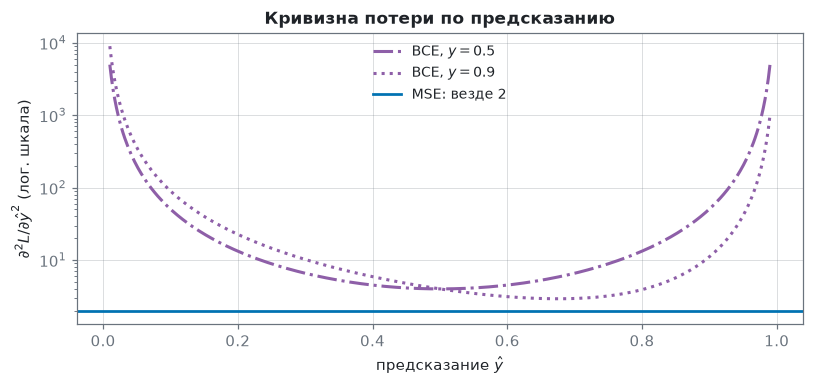

In [127]:
# Кривизна потери по предсказанию -- это вторая производная. Она показывает, 
# насколько неравномерно BCE смотрит на ошибки в разных местах диапазона.
def bce_curvature(y, p):
    return y / p ** 2 + (1.0 - y) / (1.0 - p) ** 2


points = (0.5, 0.9, 0.99)
display(
    pd.DataFrame(
        {
            "кривизна BCE (y = 0.5)": [bce_curvature(0.5, pt) for pt in points],
            "кривизна MSE": [2.0] * len(points),
        },
        index=pd.Index(points, name="предсказание")
    ).style.format("{:.1f}")
)

p_axis = np.linspace(0.01, 0.99, 400)
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for y_fixed, ls in ((0.5, "-."), (0.9, ":")):
    ax.plot(p_axis, bce_curvature(y_fixed, p_axis), color=LOSS_COLOR["BCE"], ls=ls, label=f"BCE, $y = {y_fixed}$")
ax.axhline(2.0, color=LOSS_COLOR["MSE"], ls=LOSS_STYLE["MSE"], lw=1.8, label="MSE: везде 2")
ax.set_yscale("log")
ax.set_title("Кривизна потери по предсказанию")
ax.set_xlabel(r"предсказание $\hat y$")
ax.set_ylabel(r"$\partial^2 L / \partial \hat y^2$ (лог. шкала)")
ax.legend()
fig.tight_layout()
plt.show()

**Что мы видим?**

В сценарии (б) смещения нет: BCE достигает минимума в правильной точке. Но MSE и BCE по-разному штрафуют ошибки. У MSE кривизна всегда равна 2, а у BCE она сильно увеличивается ближе к краям отрезка.

Поэтому MSE примерно одинаково учитывает ошибки во всём диапазоне, а BCE сильнее учитывает ошибки около границ. Из-за этого модель, обученная с BCE, точнее предсказывает значения у краёв, но хуже -- в середине.

Такое поведение полезно, если мы предсказываем вероятности. Но если нужно предсказывать, например, температуру, ограниченную определённым диапазоном, такое распределение ошибок может быть нежелательным.

### Сценарий (в). Нарезать диапазон на интервалы и классифицировать

Этот способ вроде бы является единственным, которым кросс-энтропию применяют к числам на практике. Диапазон делится на K интервалов, каждому примеру ставится в соответствие номер интервала, и дальше решается обычная задача классификации на $K$ классов. Предсказанием считается середина выбранного интервала.

In [133]:
K_BINS = 10
bin_edges = np.linspace(0.0, 1.0, K_BINS + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2

# Главная потеря: CE вообще не знает, что интервалы упорядочены.
true_k = 5
print("Одна и та же уверенность 0.90, поставленная на разные интервалы:")
for wrong_k, label in ((4, "соседний интервал"), (9, "интервал на другом конце")):
    probs = np.full(K_BINS, 0.01 / (K_BINS - 2))
    probs[true_k], probs[wrong_k] = 0.09, 0.90
    probs /= probs.sum()
    ce_value = ce_from_logits(to_one_hot(np.array([true_k]), K_BINS), np.log(probs).reshape(1, -1))
    scale_error = abs(bin_centers[wrong_k] - bin_centers[true_k])
    print(f"  на {label:24s}: CE = {ce_value:.4f}, ошибка по шкале = {scale_error:.1f}")
print("  Значения CE совпадают, ошибка по шкале различается в 4 раза.")

Одна и та же уверенность 0.90, поставленная на разные интервалы:
  на соседний интервал       : CE = 2.4079, ошибка по шкале = 0.1
  на интервал на другом конце: CE = 2.4079, ошибка по шкале = 0.4
  Значения CE совпадают, ошибка по шкале различается в 4 раза.


---

### Вывод по разделу 5

1. Если использовать CE для обычной регрессии, могут возникнуть проблемы. Если предсказание выходит за диапазон от 0 до 1, появляется nan, потому что логарифм отрицательного числа не определён. Но если сама цель находится за пределами этого диапазона, ошибка может не появиться. Например, при y = 3 лосс становится отрицательным и продолжает уменьшаться. В результате модель будет пытаться приблизить предсказание к границе диапазона, хотя это не означает, что она работает лучше.

2. Обрезка значений не решает проблему полностью. Можно ограничить предсказания небольшим интервалом внутри (0,1), чтобы избежать ошибок при вычислении логарифма. Но это лишь скрывает проблему: некорректные значения превращаются в обычные числа. Например, предсказание -0.3 даст лосс 27.631, а не nan.

3. Если привести цели к диапазону [0,1], CE работает корректно, но меняется характер обучения. Минимум ошибки достигается при правильном предсказании. Однако BCE сильнее штрафует ошибки около границ диапазона, а в середине -- слабее. Поэтому модель уделяет разное внимание разным участкам диапазона. Для вероятностей это может быть полезно, но для обычной регрессии не всегда подходит.

4. Если разделить значения на интервалы и использовать классификацию, теряется точность. Модель предсказывает не конкретное число, а интервал, к которому оно относится. Даже если она правильно выбрала интервал, остаётся ошибка из-за округления. Кроме того, CE не учитывает расстояние между классами: ошибка на один интервал и ошибка на четыре интервала могут давать одинаковый лосс.

5. Главный вывод: функцию потерь нужно выбирать в зависимости от задачи. CE подходит для классификации, где модель оценивает вероятность классов. Для регрессии, где нужно предсказать конкретное число, обычно лучше подходят MSE или MAE. Использовать CE для регрессии можно, но нужно понимать, как это изменит обучение и какие ограничения появятся.

---

## 6. Выводы

### Сводка: какой лосс под какую задачу выбирали?

| Задача | Особенности данных | Какой лосс выбрать | Почему | Где проверяли |
|---|---|---|---|---|
| Регрессия | Шум есть, выбросов нет | **MSE** | Хорошо подходит для данных с гауссовым шумом и позволяет получить точную оценку | Теория |
| Регрессия | Есть выбросы | **MAE** | Меньше зависит от выбросов. При 5 % выбросов ошибка составила 0.0995 против 0.4643 у MSE | Разделы 1, 3 |
| Регрессия | Выбросы возможны, но их количество неизвестно | **Huber** | Сочетает свойства MSE и MAE: небольшие ошибки учитывает как MSE, а при больших ошибках вклад одной точки в градиент ограничен сверху параметром $\delta$ | Разделы 1, 2 |
| Бинарная классификация | Два класса, дисбаланса нет | **BCE от логитов** | Градиент не становится слишком маленьким, когда модель сильно уверена в своём ответе | Раздел 2 |
| Классификация | Больше двух классов | **CE с softmax** | Учитывает вероятности всех классов сразу и помогает распределять вероятность между ними | Раздел 2 |
| Классификация | Редкий класс важнее, чем отсутствие ложных срабатываний | **Взвешенная BCE** | Помогает находить больше редких объектов: recall вырос с 0.400 до 0.850, но precision упал с 0.800 до 0.344 | Раздел 4 |
| Регрессия | Нужно предсказывать долю или вероятность от 0 до 1 | **BCE можно использовать** | Минимум достигается при правильном предсказании, но ошибки около границ диапазона штрафуются сильнее | Раздел 5 |
| Регрессия | Нужно предсказывать непрерывное число | **Дискретизация + CE не подходят** | При разбиении на интервалы теряется точность, CE не учитывает, насколько далеко предсказанный интервал от правильного: ошибка на один интервал и на четыре штрафуются одинаково (2.4079) | Раздел 5 |
| Регрессия | Цели могут быть любыми вещественными числами | **CE не подходит** | Лосс может бесконечно уменьшаться и давать неверное представление об улучшении модели | Раздел 5 |

---
## Контрольный вопрос 1. Как выбор лосса связан с постановкой задачи и распределением данных?

Коротко: функция потерь -- это одновременно и формулировка вопроса, который мы задаём данным,
и предположение о том, как устроен шум. Связь видна на трёх уровнях.

**Уровень 1. Лосс определяет, какую статистику оценивает модель.**
Если приравнять производную среднего штрафа к нулю, то для квадратичной потери получится
среднее, а для модуля -- медиана. То есть обучение с MSE оценивает среднее целевой
переменной, а обучение с MAE -- медиану. Выбросы сдвигают среднее и почти не трогают
медиану, поэтому устойчивость MAE -- не отдельное свойство, а прямое следствие того, какую
статистику он оценивает.

Значит, выбирая лосс, мы выбираем не "способ измерять ошибку", а то, какую характеристику
распределения восстанавливает модель. Поэтому вопрос "какой лосс лучше" не имеет ответа без
вопроса "что именно надо предсказать".

**Уровень 2. Лосс содержит предположение о распределении шума.**
Минимизация суммы квадратов -- это метод максимального правдоподобия при гауссовом шуме,
минимизация модулей -- при шуме Лапласа, кросс-энтропия -- при схеме Бернулли. Пока
предположение верно, соответствующий лосс работает хорошо. Как только в данных появляются
выбросы, предположение о гауссовом шуме становится ложным, и MSE начинает проигрывать.

В разделе 3 это видно на числах: на данных с 5% выбросов расхождение с истинной зависимостью
составило 0.4643 у MSE против 0.0995 у MAE и 0.1141 у Huber, то есть почти впятеро больше.
Разброс по пяти сидам при этом $\pm 0.0126$ и меньше -- на порядок меньше самого разрыва,
так что списать его на неудачную инициализацию нельзя.

Важно, что обратное тоже верно: на чистых данных с гауссовым шумом выигрывал бы уже MSE,
потому что он там является оценкой максимального правдоподобия, а MAE, оставляя от отклонения
только знак, выбрасывает полезную информацию. Поэтому правильная формулировка -- не "MAE лучше
MSE", а "устойчивость и эффективность это компромисс, и что перевесит, зависит от доли
выбросов в данных".

**Уровень 3. Лосс должен быть согласован с активацией выхода.**
Градиент кросс-энтропии по логиту равен в точности ошибке предсказания $(\hat y - y)$: дробь
$\hat y(1-\hat y)$, появившаяся от производной логарифма, сокращается с производной сигмоиды,
которая равна ровно тому же выражению. Если оставить сигмоиду, но заменить лосс на
квадратичный, сокращать будет нечего -- в градиенте останется множитель $\sigma'(z)$, который
не превышает $0.25$ и быстро убывает при удалении от нуля. То есть обучение будет тормозить
именно тогда, когда модель уверенно ошибается.

Отсюда следует, что "функция потерь" и "выходная активация" -- не два независимых выбора,
а один. В разделе 3 сеть и построена так: выходной слой линейный, а сигмоида и softmax
спрятаны внутри функций потерь.

**Предложение.** Порядок рассуждения такой: сначала что предсказываем (число, событие,
класс), потом что известно про шум и выбросы, потом какова цена разных ошибок, и только после
этого выбирается лосс. Обратный порядок -- "возьмём MSE, он привычный" -- приводит ровно к тем
эффектам, которые разобраны в разделах 3 и 5.

---
## Контрольный вопрос 2. Когда оправдан CE?

Кросс-энтропия оправдана тогда, когда модель предсказывает вероятность события, а цель --
индикатор того, произошло это событие или нет. Разберём по случаям.

**Оправдана безусловно -- классификация на три и более класса.**
Здесь у CE нет замены: нужна функция, которая оценивает распределение по всем классам сразу.
Softmax вместе с кросс-энтропией дают градиент $(\hat y - y)$ по всем логитам, и в разделе 2
проверено численно, что сумма его компонент равна нулю ($2.8\cdot10^{-17}$). Содержательно это
значит, что softmax умеет только перераспределять вероятность: прибавить уверенности одному
классу можно лишь отняв у остальных.

**Оправдана, но необязательна -- бинарная классификация.**
При двух классах задачу одинаково решают и один выход с BCE, и два выхода с CE: в разделе 4
обе модели обучены на одних данных и дали практически одинаковые метрики (accuracy 0.965
против 0.968, F-мера 0.533 против 0.581 -- различие соответствует одному примеру из 400).
Так что выбор здесь -- вопрос удобства, а не качества: CE требует лишнего выходного нейрона
и лишнего столбца вероятностей.

**Оправдана, но с оговоркой -- величины, которые по смыслу являются долей или вероятностью и лежат
в отрезке $[0,1]$.** Формально всё корректно, и смещения нет: как показано в разделе 5, минимум
BCE достигается ровно при $\hat y = y$. Но кривизна BCE растёт к границам отрезка неограниченно
(4, 50.6 и 5000.5 при предсказаниях 0.5, 0.9 и 0.99 против постоянной двойки у MSE), поэтому
модель будет точнее у краёв диапазона и грубее в середине. Если величина действительно
вероятность, такое перераспределение внимания осмысленно: разница между «почти никогда» и
«никогда» важнее, чем между 50% и 55%. А если это, скажем, температура, сжатая в отрезок, то,
скорее всего, вредно.

**Не оправдана -- регрессия по произвольным вещественным числам.** И ломается это двумя разными
способами, что показано в разделе 5:

1. Если за отрезок $[0,1]$ вышло предсказание, получается `nan`: логарифм отрицательного
   числа не определён. Отдельно стоит помнить, что обрезка по $\varepsilon$ эту ошибку прячет --
   предсказание $-0.3$ с обрезкой даёт не `nan`, а правдоподобные $27.631$.

2. Если за отрезок вышла цель, `nan` не возникает, но происходит кое-что ужаснее: лосс теряет
   ограничение снизу. При $y = 3$ значение доходит до $-55.262$ и продолжает убывать по мере
   приближения предсказания к единице, минимума внутри $(0,1)$ не существует, а градиентный
   спуск будет бесконечно прижимать предсказание к границе -- и улучшающийся лосс будет
   выглядеть как успешное обучение. Эта ошибка опаснее первой именно тем, что не отображается
   как ошибка.

**Про дискретизацию.** Непрерывную величину можно нарезать на интервалы и решать задачу как
классификацию, но кросс-энтропия при этом не видит расстояния между интервалами* в разделе 5
показано, что уверенность 0.90, поставленная на соседний интервал и на интервал вчетверо
дальше, даёт один и тот же штраф $2.4079$. Для классификации это правильно -- кошка и собака
не ближе друг к другу, чем кошка и самолёт. Для чисел неправильно: 3.1 ближе к 3.2, чем
к 9.8, и лосс обязан это учитывать.

**А если кратко?.** CE спрашивает "насколько модель была уверена в том, что произошло". Там, где
есть событие, вопрос осмыслен. Там, где есть только число, CE либо отказывается считать, либо
молча начинает решать другую задачу.
